# Training monitoring

**Final project · Intelligent museum guide** · issue #6

Deliverable 2, part 1: how do we know that a training went well, or why it did not? The learning curves (train
vs validation loss and accuracy) of the final models are in their notebooks, drawn with `plot_history` from
`src/plots.py`: `results/mlp_curves.png` and `results/resnet_curves.png`. Here we look at three more signals on
the architecture chosen for the MLP (3 hidden layers of 512 units):

1. **The learning rate**: the same network trained with a rate that is too low, good, and too high.
2. **The gradient norm of each layer** during training (Session 5), with ReLU and with the sigmoid.
3. **The activations** at the end of training: dead ReLU units, saturated sigmoid units.

The MLP is cheap to train, so every run here takes a few seconds on a CPU. There is no data augmentation and no
dropout, to see the raw behaviour of the network.

**How this notebook is organised**

- From `src/`: `load_splits`, `MLP`, `fit`, `evaluate`, `plot_compare`, `save_json` and `RESULTS_DIR`.
- Defined here: `train_with_gradient_norms`, the training loop of `src/train.py` with one more line that records
  the gradient norm of every layer after each `backward()`.
- The dictionary `monitoring` collects the numbers of the three parts; the last cell saves it in
  `results/monitoring.json`, which the diagnosis notebook reads.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

sys.path.append("..")
from src.data import load_splits
from src.models import MLP
from src.plots import plot_compare
from src.train import RESULTS_DIR, evaluate, fit, save_json

np.random.seed(0)
torch.manual_seed(0)
SIZE = 32
N_IN = 3 * SIZE * SIZE
loss_fn = nn.CrossEntropyLoss()

splits, classes = load_splits("train", size=SIZE)
X_train, y_train = splits["train"]
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(*splits["val"]), batch_size=256)
monitoring = {}

train 1050 images | per class {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}
val    225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
test   225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}


## 1. Learning rate

Three runs of 30 epochs with Adam, without early stopping, so that we see the whole curves. `fit` still reloads
the best weights at the end, but here we only look at the history. The loss is drawn on a log scale, because a
learning rate that is too high can make it explode.

lr = 1e-06 train loss    1.61 (epoch 1) -> 1.54 (epoch 30) | lowest val loss 1.55 at epoch 30, val acc there 0.311
lr = 0.0001 train loss    1.54 (epoch 1) -> 0.08 (epoch 30) | lowest val loss 1.45 at epoch  4, val acc there 0.400
lr = 0.01  train loss   10.29 (epoch 1) -> 1.39 (epoch 30) | lowest val loss 1.52 at epoch 21, val acc there 0.342


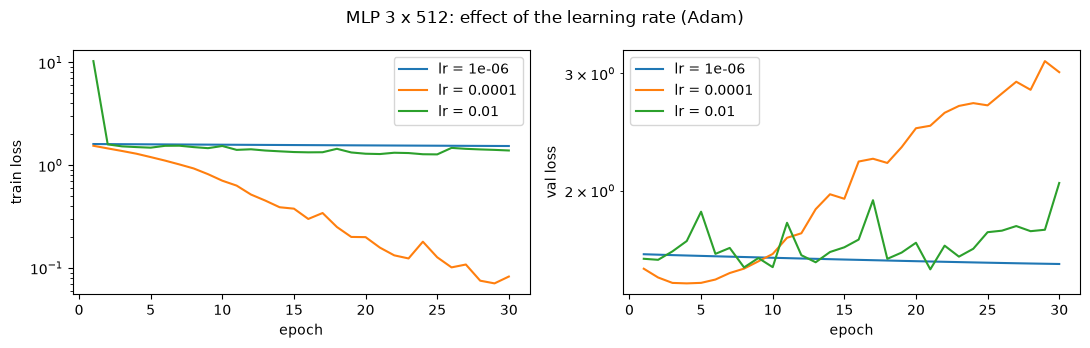

In [2]:
histories = {}
for lr in [1e-6, 1e-4, 1e-2]:
    torch.manual_seed(0)
    model = MLP(N_IN, width=512, depth=3)
    # no patience: we want the whole curve, even after the best epoch
    histories[f"lr = {lr:g}"] = fit(model, train_loader, val_loader, loss_fn,
                                    torch.optim.Adam(model.parameters(), lr=lr), n_epochs=30, verbose=False)

monitoring["learning_rate"] = {}
for name, h in histories.items():
    best = int(np.argmin(h["val_loss"]))   # the epoch that early stopping would keep
    monitoring["learning_rate"][name] = r = {
        "train_loss_epoch_1": h["train_loss"][0], "train_loss_epoch_30": h["train_loss"][-1],
        "min_val_loss": h["val_loss"][best], "min_val_loss_epoch": best + 1, "val_acc_at_min": h["val_acc"][best]}
    print(f"{name:10s} train loss {r['train_loss_epoch_1']:7.2f} (epoch 1) -> {r['train_loss_epoch_30']:.2f} (epoch 30) | "
          f"lowest val loss {r['min_val_loss']:.2f} at epoch {r['min_val_loss_epoch']:2d}, val acc there {r['val_acc_at_min']:.3f}")
plot_compare(histories, title="MLP 3 x 512: effect of the learning rate (Adam)", log=True,
             path=RESULTS_DIR / "monitoring_learning_rate.png")

**What we see.**

- **Too low (1e-6)**: the training loss barely moves (1.61 → 1.54 in 30 epochs) and stays near ln 5 = 1.61. The
  network is still close to its random initialisation (validation accuracy 0.31).
- **Good (1e-4)**: the training loss goes down steadily to 0.08. The validation loss is lowest at epoch 4
  (validation accuracy 0.40), then rises to 3.0 while the training loss keeps decreasing. This is the signature
  of overfitting, which early stopping handles.
- **Too high (1e-2)**: the first epoch explodes (training loss 10.3), then the loss stays around 1.4 and the
  validation loss oscillates. The steps are too large to settle into a minimum (validation accuracy 0.34).

## 2. Gradient norm per layer

We train the same network for 5 epochs (lr 1e-4), once with ReLU and once with the sigmoid, with the explicit
loop of `src/train.py`. After each `backward()` we record the norm of the weight gradient of each of the four
`Linear` layers. In backpropagation, the gradient of a layer is the product of the derivatives of all the
layers above it; the derivative of the sigmoid is at most 0.25, so the gradient shrinks on its way down to the
first layers (the *vanishing gradient* of Session 5).

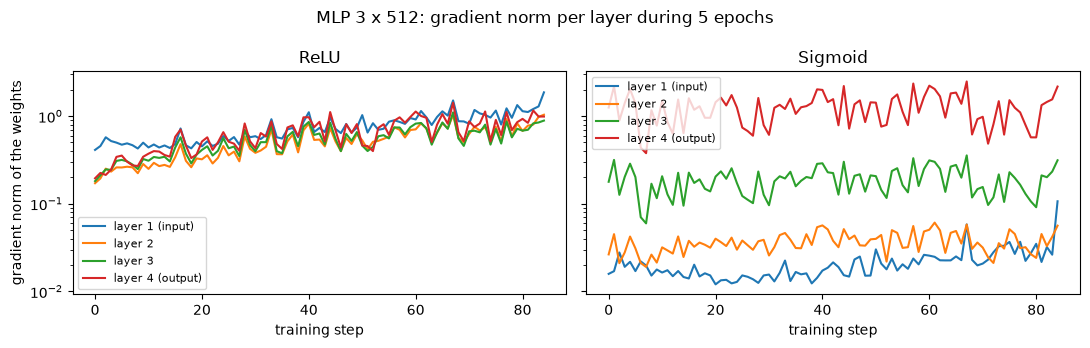

ReLU     median gradient norm per layer [0.714  0.5127 0.5211 0.6405] | output layer / input layer: 0.9
Sigmoid  median gradient norm per layer [0.0189 0.0351 0.1941 1.2956] | output layer / input layer: 68.5


In [3]:
def train_with_gradient_norms(model, n_epochs=5, lr=1e-4):
    """The training loop of src/train.py, plus the gradient norm of every Linear layer at each step."""
    linears = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    norms = []
    torch.manual_seed(0)
    model.train()
    for epoch in range(n_epochs):
        for xb, yb in train_loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            # after backward(), .grad holds this step's gradient; its L2 norm sums it up in one number
            norms.append([layer.weight.grad.norm().item() for layer in linears])
            optimizer.step()
    return np.array(norms)                     # (steps, layers)


activations = {"ReLU": nn.ReLU, "Sigmoid": nn.Sigmoid}
trained, grad_norms = {}, {}
for name, act in activations.items():
    torch.manual_seed(0)
    trained[name] = MLP(N_IN, width=512, depth=3, activation=act)
    grad_norms[name] = train_with_gradient_norms(trained[name])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (name, norms) in zip(axes, grad_norms.items()):
    for k in range(norms.shape[1]):
        label = "layer 1 (input)" if k == 0 else f"layer {k + 1} (output)" if k == norms.shape[1] - 1 else f"layer {k + 1}"
        ax.plot(norms[:, k], label=label)
    ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_title(name); ax.legend(fontsize=8)
axes[0].set_ylabel("gradient norm of the weights")
fig.suptitle("MLP 3 x 512: gradient norm per layer during 5 epochs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "monitoring_gradients.png", dpi=120)
plt.show()

monitoring["gradient_norms"] = {}
for name, norms in grad_norms.items():
    median = np.median(norms, axis=0)       # per layer, over all the steps: robust to a few spikes
    monitoring["gradient_norms"][name] = {"median_per_layer": median.tolist(),
                                          "last_over_first": float(median[-1] / median[0])}
    print(f"{name:8s} median gradient norm per layer {np.round(median, 4)} | "
          f"output layer / input layer: {median[-1] / median[0]:.1f}")

**What we see.** With ReLU, the four layers get gradients of the same order (median 0.5 to 0.7, a
ratio of 0.9 between the output and the input layer), so every layer learns. With the sigmoid, the gradient of
the first layer is **68 times smaller** than that of the output layer (0.019 against 1.30): the layer that reads
the pixels barely learns. This is why the sigmoid network needed about 18 epochs to reach its best validation
loss in the MLP notebook, against 4 with ReLU.

## 3. Activations

At the end of these two trainings, we pass 256 training images through each network and look at the output of
each hidden layer:

- with **ReLU**, a unit is *dead* if it outputs 0 for every image: it no longer receives any gradient (Session 5);
- with the **sigmoid**, an output is *saturated* if it is below 0.05 or above 0.95, where the derivative is almost
  zero. The standard deviation shows how much the outputs still differ from one image to the other.

In [4]:
x_probe = X_train[:256]
monitoring["activations"] = {}
for name, model in trained.items():
    model.eval()
    stats, a = [], x_probe
    with torch.no_grad():
        for layer in model.layers:
            a = layer(a)
            if isinstance(layer, activations[name]):     # the output of an activation is a hidden layer
                if name == "ReLU":
                    # dead unit: it outputs 0 for all 256 paintings, so it gets no gradient
                    stats.append({"dead_units": (a == 0).all(dim=0).float().mean().item(),
                                  "zero_outputs": (a == 0).float().mean().item()})
                else:
                    stats.append({"saturated_outputs": ((a < 0.05) | (a > 0.95)).float().mean().item(),
                                  "std": a.std().item()})
    monitoring["activations"][name] = stats
    print(f"{name} (val acc {evaluate(model, val_loader, loss_fn)[1]:.3f})")
    for k, s in enumerate(stats, start=1):
        print(f"  hidden layer {k}: " + ", ".join(f"{key} {value:.3f}" for key, value in s.items()))

save_json(monitoring, RESULTS_DIR / "monitoring.json")

ReLU (val acc 0.356)
  hidden layer 1: dead_units 0.000, zero_outputs 0.494
  hidden layer 2: dead_units 0.004, zero_outputs 0.375
  hidden layer 3: dead_units 0.033, zero_outputs 0.355
Sigmoid (val acc 0.333)
  hidden layer 1: saturated_outputs 0.299, std 0.360
  hidden layer 2: saturated_outputs 0.000, std 0.197
  hidden layer 3: saturated_outputs 0.000, std 0.093


**What we see.** The ReLU network is healthy: no dead unit in the first layer and at most 3.3 % in the third.
About half of the outputs are zero, which is the normal sparsity of ReLU. With the sigmoid, 30 % of the outputs
of the first layer are saturated, so their derivative is almost zero. The next layers output values that barely
differ from one painting to the other (standard deviation 0.20, then 0.09), so little information reaches the
output. Both measures agree with the gradients.

## What we take from it: a monitoring checklist

| Signal | Healthy | Problem | Seen in this project |
|---|---|---|---|
| Loss at the start | close to ln 5 = 1.61 | much larger: bad initialisation or lr too high | 1.61 (MLP); 10.3 at epoch 1 with lr 1e-2 |
| Training loss | decreases steadily | flat: lr too low; explodes or oscillates: lr too high | flat with 1e-6, explodes with 1e-2 |
| Train vs validation loss | both decrease | validation rises while training decreases: overfitting | MLP from epoch 4, ResNet from epoch 3 |
| Gradient norm per layer | same order in every layer | first layers much smaller: vanishing gradient | × 68 with the sigmoid, × 0.9 with ReLU |
| Activations | few dead or saturated units | many dead ReLUs, saturated sigmoids | ≤ 3.3 % dead ReLUs, 30 % saturated sigmoids |

The numbers are saved in `results/monitoring.json` and reused in the failure diagnosis (issue #7).